### imports and md

In [54]:
from IPython.display import display,Image as IpyImage,Markdown
from pathlib import Path

In [ ]:
md_file_name = 'leviathan-2023.md'
Markdown(Path(md_file_name).read_text())

<!-- page 0 -->

# Fast Inference from Transformers via Speculative Decoding

**Yaniv Leviathan** \(^{*1}\) **Matan Kalman** \(^{*1}\) **Yossi Matias** \(^{1}\)

### Abstract

Inference from large autoregressive models like Transformers is slow - decoding \(K\) tokens takes \(K\) serial runs of the model. In this work we introduce *speculative decoding* - an algorithm to sample from autoregressive models faster *without any changes to the outputs*, by computing several tokens in parallel. At the heart of our approach lie the observations that (1) hard language-modeling tasks often include easier subtasks that can be approximated well by more efficient models, and (2) using speculative execution and a novel sampling method, we can make exact decoding from the large models faster, by running them in parallel on the outputs of the approximation models, potentially generating several tokens concurrently, and without changing the distribution. Our method can accelerate existing off-the-shelf models without retraining or architecture changes. We demonstrate it on T5-XXL and show a **2X-3X** acceleration compared to the standard T5X implementation, with identical outputs.

## 1. Introduction

Large autoregressive models, notably large Transformers (Vaswani et al., 2017), are much more capable than smaller models, as is evidenced countless times in recent years e.g., in the text or image domains, like GPT-3 (Brown et al., 2020), LaMDA (Thoppilan et al., 2022), Parti (Yu et al., 2022), and PaLM (Chowdhery et al., 2022). Unfortunately, a single decode step from these larger models is significantly slower than a step from their smaller counterparts, and making things worse, these steps are done serially - decoding \(K\) tokens takes \(K\) serial runs of the model.

Given the importance of large autoregressive models and specifically large Transformers, several approaches were developed to make inference from them faster. Some approaches aim to reduce the inference cost for *all* inputs equally (e.g. Hinton et al., 2015; Jaszczur et al., 2021; Hubara et al., 2016; So et al., 2021; Shazeer, 2019). Other approaches stem from the observation that not all inference steps are born alike - some require a very large model, while others can be approximated well by more efficient models. These *adaptive computation* methods (e.g. Han et al., 2021; Sukhbaatar et al., 2019; Schuster et al., 2021; Scardapane et al., 2020; Bapna et al., 2020; Elbayad et al., 2019; Schwartz et al., 2020) aim to use less compute resources for easier inference steps. While many of these solutions have proven extremely effective in practice, they usually require changing the model architecture, changing the training-procedure and re-training the models, and don't maintain identical outputs.

The key observation above, that some inference steps are "harder" and some are "easier", is also a key motivator for our work. We additionally observe that inference from large models is often not bottlenecked on arithmetic operations, but rather on memory bandwidth and communication, so additional computation resources might be available. Therefore we suggest increasing concurrency as a complementary approach to using an adaptive amount of computation. Specifically, we are able to accelerate inference without changing the model architectures, without changing the training-procedures or needing to re-train the models, and without changing the model output distribution. This is accomplished via *speculative execution*.

Speculative execution (Burton, 1985; Hennessy & Patterson, 2012) is an optimization technique, common in processors, where a task is performed in parallel to verifying if it's actually needed - the payoff being increased concurrency. A well-known example of speculative execution is branch prediction. For speculative execution to be effective, we need an efficient mechanism to suggest tasks to execute that are likely to be needed. In this work, we generalize speculative execution to the stochastic setting - where a task *might* be needed with some probability. Applying this to decoding from autoregressive models like Transformers, we sample generations from more efficient *approximation models* as speculative prefixes for the slower *target models*. With a novel sampling method, *speculative sampling*, we maximize the probability of these speculative tasks to

\rule{0.5\textwidth}{0.4pt}  
\(^{*}\)Equal contribution \(^{1}\)Google Research, Mountain View, CA, USA. Correspondence to: Yaniv Leviathan \(<leviathan@google.com>\).

Proceedings of the \(40^{th}\) International Conference on Machine Learning, Honolulu, Hawaii, USA. PMLR 202, 2023. Copyright 2023 by the author(s).

<!-- page 1 -->

![Figure 1](speculative-decoding//1_figure_1.png)

*Figure 1. Our technique illustrated in the case of unconditional language modeling. Each line represents one iteration of the algorithm. The **green** tokens are the suggestions made by the approximation model (here, a GPT-like Transformer decoder with 6M parameters trained on lm1b with 8k tokens) that the target model (here, a GPT-like Transformer decoder with 97M parameters in the same setting) accepted, while the **red** and **blue** tokens are the rejected suggestions and their corrections, respectively. For example, in the first line the target model was run only once, and 5 tokens were generated.*

be accepted, while guaranteeing that the outputs from our system have the same distribution as those from the target model alone. For example, the sentence in Figure 1, consisting of 38 tokens, was generated by our method with only 9 serial runs of a larger target model (97M parameters) thanks to a smaller and more efficient approximation model (6M parameters), while the probability of generating it is unchanged.

We analyze our method in a variety of tasks and model sizes: unconditional generation from a 97M parameter GPT-like model trained on lm1b, English to German translation and news article summarization with an 11B parameters T5-XXL model, and a dialog task with a 137B parameter LaMDA model. We implement our method and compare actual walltimes for T5-XXL to those of the robust T5X implementation (Roberts et al., 2022), showing an out-of-the-box latency improvement of **2X-3X**, without any change to the outputs (Section 4).

Our method is easy to employ in actual production settings, doesn't require training new models, and doesn't change the outputs. Therefore, in common situations where memory bandwidth is the bottleneck, and compute resources are available, it may be a good default to accelerate sampling from autoregressive models like Transformers.

To summarize, our main contributions are: (1) A generalization of speculative execution to the stochastic setting, with a novel sampling method we call *speculative sampling*, and (2) A decoding mechanism we call *speculative decoding* that can accelerate decoding from autoregressive models, without any change to the model architectures, training regimes and output distributions.

## 2. Speculative Decoding

### 2.1. Overview

Let \( M_p \) be the target model, inference from which we're trying to accelerate, and \( p(x_t|x_{<t}) \) the distribution we get from the model for a prefix \( x_{<t} \). Let \( M_q \) be a more efficient approximation model for the same task, and denote by \( q(x_t|x_{<t}) \) the distribution we get from the model for a prefix \( x_{<t} \)<sup>1</sup>. The core idea is to (1) use the more efficient model \( M_q \) to generate \( \gamma \in \mathbb{Z}^+ \) completions (see Section 3.5 for how to optimally choose this parameter), then (2) use the target model \( M_p \) to evaluate all of the guesses and their respective probabilities from \( M_q \) *in parallel*, accepting all those that *can* lead to an identical distribution, and (3) sampling an additional token from an adjusted distribution to fix the first one that was rejected, or to add an additional one if they are all accepted. That way, each parallel run of the target model \( M_p \) will produce at least one new token (so the number of serial runs of the target model can never, even in the worst case, be larger than the simple autoregressive method), but it can potentially generate many new tokens, up to \( \gamma + 1 \), depending on how well \( M_q \) approximates \( M_p \).

### 2.2. Standardized Sampling

First, note that while there are many methods and parameters of sampling, like argmax, top-k, nucleus, and setting a temperature, and popular implementations usually treat them differently at the logits level, they can all easily be cast into standard sampling from an adjusted probability distribution. For example, argmax sampling is equivalent to zeroing out non-max elements of the distribution and normalizing. We can therefore only deal with standard sampling from a

---

<sup>1</sup>We'll use \( p(x) \) to denote \( p(x_t|x_{<t}) \) whenever the prefix \( x_{<t} \) is clear from the context, and similarly for \( q(x) \).

<!-- page 2 -->

## 2.3. Speculative Sampling

To sample \( x \sim p(x) \), we instead sample \( x \sim q(x) \), keeping it if \( q(x) \leq p(x) \), and in case \( q(x) > p(x) \) we reject the sample with probability \( 1 - \frac{p(x)}{q(x)} \) and sample \( x \) again from an adjusted distribution \( p'(x) = norm(max(0, p(x) - q(x))) \) instead. It's easy to show (see Appendix A.1) that for any distributions \( p(x) \) and \( q(x) \), and \( x \) sampled in this way, indeed \( x \sim p(x) \).

Given the distribution \( q(x) \) obtained from running \( M_q \) on a conditioning *prefix*, we can sample a token \( x_1 \sim q(x) \). We then calculate the distribution \( p(x) \) by running \( M_p \) on *prefix* while in parallel speculatively calculating the distribution of the next token \( x_2 \) by running \( M_p \) on \( prefix + [x_1] \). Once both computations complete, we proceed as per above: If \( x_1 \) is rejected, we discard the computation of \( x_2 \) and re-sample \( x_1 \) from an adjusted distribution, and if \( x_1 \) is accepted, we keep both tokens. Algorithm 1 generalizes this idea to sample between 1 and \( \gamma + 1 \) tokens at once.

---
**Algorithm 1** SpeculativeDecodingStep
---
**Inputs:** \( M_p, M_q, prefix \).
▷ Sample \( \gamma \) guesses \( x_{1,...,\gamma} \) from \( M_q \) autoregressively.
**for** \( i = 1 \) **to** \( \gamma \) **do**
\( q_i(x) \leftarrow M_q(prefix + [x_1, \dots, x_{i-1}]) \)
\( x_i \sim q_i(x) \)
**end for**
▷ Run \( M_p \) in parallel.
\( p_1(x), \dots, p_{\gamma+1}(x) \leftarrow M_p(prefix), \dots, M_p(prefix + [x_1, \dots, x_\gamma]) \)
▷ Determine the number of accepted guesses \( n \).
\( r_1 \sim U(0, 1), \dots, r_\gamma \sim U(0, 1) \)
\( n \leftarrow \min(\{i - 1 \mid 1 \leq i \leq \gamma, r_i > \frac{p_i(x)}{q_i(x)}\} \cup \{\gamma\}) \)
▷ Adjust the distribution from \( M_p \) if needed.
\( p'(x) \leftarrow p_{n+1}(x) \)
**if** \( n < \gamma \) **then**
\( p'(x) \leftarrow norm(max(0, p_{n+1}(x) - q_{n+1}(x))) \)
**end if**
▷ Return one token from \( M_p \), and \( n \) tokens from \( M_q \).
\( t \sim p'(x) \)
**return** \( prefix + [x_1, \dots, x_n, t] \)
---

## 3. Analysis

### 3.1. Number of Generated Tokens

Let's analyze the reduction factor in the number of serial calls to the target model, or equivalently, the expected number of tokens produced by a single run of Algorithm 1.

**Definition 3.1.** The *acceptance rate* \( \beta_{x_{<t}} \), given a prefix \( x_{<t} \), is the probability of accepting \( x_t \sim q(x_t|x_{<t}) \) by speculative sampling, as per Section 2.3\(^2\).

\( E(\beta) \) is then a natural measure of how well \( M_q \) approximates \( M_p \). If we make the simplifying assumption that the \( \beta \)s are i.i.d., and denote \( \alpha = E(\beta) \), then the number of tokens produced by a single run of Algorithm 1 is a capped geometric variable, with success probability \( 1 - \alpha \) and cap \( \gamma + 1 \), and the expected number of tokens generated by Algorithm 1 satisfies Equation (1). See Figure 2.

\[ E(\# \text{ generated tokens}) = \frac{1 - \alpha^{\gamma+1}}{1 - \alpha} \tag{1} \]

![Figure 2](speculative-decoding//2_figure_2.png)
*Figure 2. The expected number of tokens generated by Algorithm 1 as a function of \( \alpha \) for various values of \( \gamma \).*

### 3.2. Calculating \( \alpha \)

We'll now derive a simple formula for calculating \( \alpha \) given a prefix and the two models \( M_p \) and \( M_q \). We start by defining a natural divergence \( D_{LK} \):

**Definition 3.2.** \( D_{LK}(p, q) = \sum_x |p(x) - M(x)| = \sum_x |q(x) - M(x)| \) where \( M(x) = \frac{p(x)+q(x)}{2} \).

**Lemma 3.3.** \( D_{LK}(p, q) = 1 - \sum_x \min(p(x), q(x)) \)

**Proof.** \( D_{LK}(p, q) = \sum_x |p(x) - M(x)| = \sum_x \frac{|p-q|}{2} = 1 - \sum_x \frac{p+q-|p-q|}{2} = 1 - \sum_x \min(p(x), q(x)) \) ◻

From Lemma 3.3 we immediately get the following results:

---
\(^2\)As before, we'll omit the \( x_{<t} \) subscript whenever the prefix is clear from the context.

<!-- page 3 -->

### Fast Inference from Transformers via Speculative Decoding

**Corollary 3.4.** \( D_{LK}(p, q) \) *is a symmetric divergence in \( [0, 1] \).*
\( D_{LK}(p, q) = 0 \iff p = q \).
\( D_{LK}(p, q) = 1 \iff p \text{ and } q \text{ have disjoint support} \).

**Theorem 3.5.** \( \beta = 1 - D_{LK}(p, q) \)

*Proof.* \[
\beta = E_{x \sim q(x)} \begin{cases} 1 & q(x) \le p(x) \\ \frac{p(x)}{q(x)} & q(x) > p(x) \end{cases} = E_{x \sim q(x)} \min(1, \frac{p(x)}{q(x)}) = \sum_x \min(p(x), q(x))
\]

Finally we get:
**Corollary 3.6.** \( \alpha = 1 - E(D_{LK}(p, q)) = E(\min(p, q)) \)

See Table 3 for empirically observed \( \alpha \) values in our experiments.

### 3.3. Walltime Improvement

We’ve shown that with the i.i.d. assumption our algorithm reduces the number of calls to the target model by a factor of \( \frac{1-\alpha^{\gamma+1}}{1-\alpha} \). Note that speculative execution in general, and our algorithm in particular, assume that we have enough compute resources to support the increased concurrency (Section 3.4). For the walltime analysis, we’ll assume that we can run \( \gamma + 1 \) concurrent evaluations of \( M_p \) in parallel without increasing the walltime. To get the total walltime improvement, we now consider the cost of running the approximation model \( M_q \).

**Definition 3.7.** Let \( c \), the *cost coefficient*, be the ratio between the time for a single run of \( M_q \) and the time for a single run of \( M_p \).

Note that unlike \( \alpha \) which is an intrinsic property of the models and the task, the value of \( c \) depends on the hardware configuration and software implementation details. In our experiments where \( M_q \) is typically a couple of orders of magnitude smaller than \( M_p \), \( c \) was always less than 0.05 and often negligibly close to 0.

**Theorem 3.8.** *The expected improvement factor in total walltime by Algorithm 1 is \( \frac{1-\alpha^{\gamma+1}}{(1-\alpha)(\gamma c+1)} \).*

*Proof.* Denote the cost of running a single step of \( M_p \) by \( T \). Now, each run of Algorithm 1 costs \( T c \gamma + T \) (for running the approximation model \( M_q \) \( \gamma \) times and running \( M_p \) once) and according to Equation (1) produces \( \frac{1-\alpha^{\gamma+1}}{1-\alpha} \) tokens on average. So the overall expected cost for producing a token with Algorithm 1 is \( \frac{(c \gamma+1)(1-\alpha)}{1-\alpha^{\gamma+1}} T \). Since the cost of producing a single token with the standard decoding algorithm is \( T \), we get the desired result. ◻

Note that Theorem 3.8 assumes long enough generations (for example, since we run \( M_p \) at least once, the improvement factor is capped by the number of generated tokens).

**Corollary 3.9.** *If \( \alpha > c \), there exists \( \gamma \) for which we’ll get an improvement, and the improvement factor will be at least \( \frac{1+\alpha}{1+c} \).*

*Proof.* If we get an improvement for \( \gamma \), we’d also get an improvement for any \( 0 < \gamma^* < \gamma \), so for our method to yield an improvement, we can evaluate Theorem 3.8 for \( \gamma = 1 \), yielding \( \frac{1-\alpha^2}{(1-\alpha)(c+1)} = \frac{1+\alpha}{1+c} \). ◻

### 3.4. Number of Arithmetic Operations

Algorithm 1 does \( \gamma+1 \) runs of \( M_p \) in parallel, so the number of *concurrent* arithmetic operations grows by a factor of \( \gamma+1 \). Now, since Algorithm 1 produces at most \( \gamma+1 \) tokens per run, the *total* number of arithmetic operations might be higher than that of the standard decoding algorithm. When we accept the sample from \( M_q \) the increased concurrency is ‘‘free’’ and the total number of operations isn’t increased⁳. When we reject a guess though, computation is wasted. Let’s now analyze the effect of our method on the total number of arithmetic operations.

**Definition 3.10.** Let \( \hat{c} \) be the ratio of arithmetic operations per token of the approximation model \( M_q \) to that of the target model \( M_p \).

**Theorem 3.11.** *The expected factor of increase in the number of total operations of Algorithm 1 is \( \frac{(1-\alpha)(\gamma\hat{c}+\gamma+1)}{1-\alpha^{\gamma+1}} \).*

*Proof.* Denote by \( \hat{T} \) the number of arithmetic operations done by a standard decoding baseline per token, i.e. the number of operations of a single run of \( M_p \). Then a single iteration of Algorithm 1 costs \( \hat{T}\hat{c}\gamma + \hat{T}(\gamma + 1) \) operations (for \( \gamma \) runs of \( M_q \) and \( \gamma + 1 \) parallel runs of \( M_p \)). Dividing by the expected number of tokens produced by Algorithm 1, i.e. Equation (1), and by \( \hat{T} \), we get the desired result. ◻

If \( \alpha \) is low, the increase in the number of arithmetic operations is high, and vice-versa. Note that for Transformer decoders, the total number of arithmetic operations by Algorithm 1 (not counting runs of \( M_q \)) can be bounded from above by a single run of the same-size Transformer encoder.

Unlike the total number of arithmetic operations, the total number of memory accesses can go down with our method. Specifically, the target model’s weights and KV cache can be read once per execution of Algorithm 1, so the number of memory accesses for reading them shrinks by a factor of \( \frac{1-\alpha^{\gamma+1}}{1-\alpha} \), according to Equation (1).

### 3.5. Choosing \( \gamma \)

Given \( c \) and \( \alpha \) and assuming enough compute resources (see Section 3.4), the optimal \( \gamma \) is the one maximizing the wall-

———————
⁳ Neglecting the cost of \( M_q \).

<!-- page 4 -->

## Fast Inference from Transformers via Speculative Decoding

![Figure 3](speculative-decoding//4_figure_3.png)

*Figure 3. The optimal \( \gamma \) as a function of \( \alpha \) for various values of \( c \).*

time improvement equation (Theorem 3.8): \( \frac{1-\alpha^{\gamma+1}}{(1-\alpha)(\gamma c+1)} \). Since \( \gamma \) is an integer, it can be easily found numerically, see Figure 3.

Table 1 and Figure 4 illustrate the trade-off between inference speed and the total number of arithmetic operations for various values of \( \alpha \) and \( \gamma \), assuming \( c = \hat{c} = 0 \). Figure 5 shows a simplified trace diagram.

*Table 1. The total number of arithmetic operations and the inference speed vs the baseline, for various values of \( \gamma \) and \( \alpha \), assuming \( c = \hat{c} = 0 \).*

| \( \alpha \) | \( \gamma \) | OPERATIONS | SPEED |
| :--- | :--- | :--- | :--- |
| 0.6 | 2 | 1.53X | 1.96X |
| 0.7 | 3 | 1.58X | 2.53X |
| 0.8 | 2 | 1.23X | 2.44X |
| 0.8 | 5 | 1.63X | 3.69X |
| 0.9 | 2 | 1.11X | 2.71X |
| 0.9 | 10 | 1.60X | 6.86X |

Instead of picking a single value for \( \gamma \) based on \( \alpha \), since the \( \beta \)s aren't constant, we could get further improvement by predicting the value of \( \beta \) and accordingly varying the value of \( \gamma \) during the run of Algorithm 1. To get an upper bound on the additional improvement factor, assume we had an oracle for \( \gamma \). We would then have \( E(\# \text{ generated tokens}) = \frac{1}{1-\alpha} \). For typical values of \( c \) and \( \alpha \), and assuming unbounded compute resources, the enhanced walltime improvement factor can be up to \( \sim 60\% \) higher than the improvement factor with a fixed \( \gamma \). We leave exploring this for future work<sup>4</sup>.

### 3.6. Approximation Models

Speculative sampling, and therefore speculative decoding, guarantee an identical output distribution for any choice of approximation model \( M_q \) without restriction (see Appendix A.1). In our experiments, we mostly tested existing off-the-shelf smaller Transformers as the approximation models. Further, we only tested approximation models of the same architecture as the target models \( M_p \) and using the same probability standardization. In this setup, choosing \( M_q \) to be around two orders of magnitude smaller than \( M_p \) usually performed best, balancing \( \alpha \) and \( c \) (Theorem 3.8).

Another type of approximation models, *negligible-cost models*, are those for which \( c \approx 0 \), i.e. approximation models with a negligible cost relative to the target model. In this case, we get an expected walltime improvement of \( \frac{1-\alpha^{\gamma+1}}{1-\alpha} \), which is bounded from above by \( \frac{1}{1-\alpha} \) (we approach equality if \( \gamma \) is large). One interesting type of negligible-cost approximation models are n-gram models, where the evaluation amounts to a table lookup. Interestingly, in empirical tests (Section 4.2) we get non zero \( \alpha \)s even for these trivial n-gram models. For example, for the English-German translation task, with \( M_p \) being T5-XXL 11B and \( M_q \) being a trivial bigram model, we get \( \alpha \approx 0.2 \) which leads to an inference speed improvement factor of 1.25X with \( \gamma = 3 \).

Other simple heuristics can be used as negligible-cost approximation models. For example, in cases where long sequences are likely to repeat, such as for summarization tasks or chat-like interfaces<sup>5</sup>, an approximation model that simply

![Figure 4](speculative-decoding//4_figure_4.png)

*Figure 4. The speedup factor and the increase in number of arithmetic operations as a function of \( \alpha \) for various values of \( \gamma \).*

---
<sup>4</sup>The above bound assumes that we still run \( M_p \) to verify the oracle's predictions. If we skip those verifications the bound doesn't hold and we would get a substantial additional improvement.

<sup>5</sup>E.g. where a user and a language model iterate on content, like text or code ("can you rewrite this story but change the ending", "can you make this function also do X").

<!-- page 5 -->

![Figure 5](speculative-decoding//5_figure_5.png)

*Figure 5. A simplified trace diagram for a full encoder-decoder Transformer stack. The top row shows speculative decoding with \(\gamma = 7\) so each of the calls to \(M_p\) (the purple blocks) is preceded by 7 calls to \(M_q\) (the blue blocks). The yellow block on the left is the call to the encoder for \(M_p\) and the orange block is the call to the encoder for \(M_q\). Likewise the middle row shows speculative decoding with \(\gamma = 3\), and the bottom row shows standard decoding.*

copies tokens from the context in case we find a matching prefix, might yield high values of \(\alpha\). These parameter-less approximation models, have the additional advantage of being even simpler to deploy from a production standpoint.

Another type of approximation models that can be used by speculative decoding are non-autoregressive models, like those from (Stern et al., 2018). Then, instead of the autoregressive loop in Algorithm 1 we'd just call the non-autoregressive model once.

A final example, interesting mostly from a theoretical perspective, is an approximation model which chooses tokens at random, which guarantees some improvement (although very small) for all models \(M_p\).

### 4. Experiments

#### 4.1. Empirical Walltime Improvement

We implement our algorithm and compare it to the implementation in the T5X codebase for accelerating T5-XXL.

**Setup** We test a standard encoder-decoder T5 version 1.1 model (Raffel et al., 2020) on two tasks from the T5 paper: (1) English to German translation fine tuned on WMT EnDe, and (2) Text summarization fine tuned on CCN/DM. For both tasks, we use T5-XXL (11B) for \(M_p\). For the approximation model \(M_q\) we test several existing configurations, namely T5-large (800M), T5-base (250M), and T5-small (77M) (Raffel et al., 2020). We use existing checkpoints for all models. We measure walltime improvements with a batch size of 1 on a single TPU-v4 for both argmax sampling (temp=0) and standard sampling (temp=1).

**Results** Table 2 shows the empirical results from our method. We see that T5-small (77M), with a good balance of \(c\) and \(\alpha\), provides the highest speedup out of the tested approximation models. As expected we see that \(\alpha\) increases with the size of the approximation model. Interestingly, \(\alpha\) and walltime improvement are higher for argmax sampling (temp=0). We observe speedups of 2.6X (temp=1) and 3.4X (temp=0) on the translation task and slightly lower speedups of 2.3X (temp=1) and 3.1X (temp=0) for the summarization task. These empirical results match well with the theoretical predictions, with some variance due to implementation details (see Appendix A.3).

*Table 2. Empirical results for speeding up inference from a T5-XXL 11B model.*

| TASK | \(M_q\) | TEMP | \(\gamma\) | \(\alpha\) | SPEED |
| :--- | :--- | :--- | :--- | :--- | :--- |
| ENDE | T5-SMALL ★ | 0 | 7 | 0.75 | **3.4X** |
| ENDE | T5-BASE | 0 | 7 | 0.8 | 2.8X |
| ENDE | T5-LARGE | 0 | 7 | 0.82 | 1.7X |
| ENDE | T5-SMALL ★ | 1 | 7 | 0.62 | **2.6X** |
| ENDE | T5-BASE | 1 | 5 | 0.68 | 2.4X |
| ENDE | T5-LARGE | 1 | 3 | 0.71 | 1.4X |
| CNNDM | T5-SMALL ★ | 0 | 5 | 0.65 | **3.1X** |
| CNNDM | T5-BASE | 0 | 5 | 0.73 | 3.0X |
| CNNDM | T5-LARGE | 0 | 3 | 0.74 | 2.2X |
| CNNDM | T5-SMALL ★ | 1 | 5 | 0.53 | **2.3X** |
| CNNDM | T5-BASE | 1 | 3 | 0.55 | 2.2X |
| CNNDM | T5-LARGE | 1 | 3 | 0.56 | 1.7X |

#### 4.2. Empirical \(\alpha\) Values

While we only implemented our method for T5, we measured \(\alpha\) values for various tasks, sampling methods, target models \(M_p\), and approximation models \(M_q\). Specifically, we evaluated the expectation from Corollary 3.6 on 10K tokens generated by \(M_p\), for each of the settings below.

**GPT-like (97M params)** We test a decoder-only Transformer model on unconditional language generation, trained on lm1b (Chelba et al., 2013). The model here is a GPT-like Transformer decoder with Gelu activations (Hendrycks & Gimpel, 2016). For \(M_q\) we experimented with a Trans

<!-- page 6 -->

former decoder model with 6M parameters: dim 256, dim feed-forward 1024, 2 layers, 4 attention heads, as well as simple unigram and bigram models. \(M_p\) has 97M parameters: dim 768, dim feed-forward 3072, 12 layers, 12 attention heads. We used Bert tokenization (Devlin et al., 2019) with 8k tokens for all models.

**LaMDA (137B params)** We tested a decoder only LaMDA model on a dialog task (Thoppilan et al., 2022). We used existing checkpoints from LaMDA 137B as \(M_p\) and LaMDA 8B, LaMDA 2B, and LaMDA 100M for \(M_q\).

See Section 4.1 for the setup of the T5-XXL (11B params) model.

Table 3 summarizes the \(\alpha\) values for the tested cases. We observe that approximation models that are a couple of orders of magnitude smaller than the target model tend to produce \(\alpha\) values between 0.5 and 0.9. Interestingly, we also note that for all models, the sharper the adjusted distribution, the higher the \(\alpha\) values. Finally, we note that even trivial unigram and bigram approximations yield non negligible \(\alpha\) values. For example, for the case of English to German translation, the bigram model has an \(\alpha\) value of 0.2, and since \(c = 0\) in this case, yields a 1.25X speed improvement, which is surprisingly high for this trivial approximation model (but is still lower than the speedup we get from using T5-small as the approximation model).

### 5. Related work

The efficiency of inference from large models was studied extensively (Dehghani et al., 2021). Many approaches aim to speed up inference from large models in general, and autoregressive models like Transformers in particular. Numerous techniques try to make inference more efficient for all tokens, e.g. distillation (Hinton et al., 2015), sparcification (Jaszczur et al., 2021), quantization (Hubara et al., 2016), and architecture modification (So et al., 2021; Shazeer, 2019). Closer to our approach are adaptive computation methods which adapt the amount of computation to problem difficulty (Han et al., 2021). Examples include attending to a subset of the inputs (Sukhbaatar et al., 2019), and early exits (Schuster et al., 2021; Scardapane et al., 2020; Bapna et al., 2020; Elbayad et al., 2019; Schwartz et al., 2020). Notably, Wisdom of Committees (Schwartz et al., 2020) leverages off-the-shelf smaller models, but is an adaptive computation approach, and so it uses a heuristic to determine when to stop, losing the guarantee of identical outputs to those of the target models. In general, adaptive computation methods usually learn, either within the model itself or with an auxiliary model, when a computation shortcut can be taken. Usually, these methods save on both inference time and arithmetic operations, but require a change of architecture, a change of training procedure and training custom models or

| \(M_p\) | \(M_q\) | SMPL | \(\alpha\) |
| :--- | :--- | :--- | :--- |
| GPT-LIKE (97M) | UNIGRAM | T=0 | 0.03 |
| GPT-LIKE (97M) | BIGRAM | T=0 | 0.05 |
| GPT-LIKE (97M) | GPT-LIKE (6M) | T=0 | 0.88 |
| GPT-LIKE (97M) | UNIGRAM | T=1 | 0.03 |
| GPT-LIKE (97M) | BIGRAM | T=1 | 0.05 |
| GPT-LIKE (97M) | GPT-LIKE (6M) | T=1 | 0.89 |
| T5-XXL (ENDE) | UNIGRAM | T=0 | 0.08 |
| T5-XXL (ENDE) | BIGRAM | T=0 | 0.20 |
| T5-XXL (ENDE) | T5-SMALL | T=0 | 0.75 |
| T5-XXL (ENDE) | T5-BASE | T=0 | 0.80 |
| T5-XXL (ENDE) | T5-LARGE | T=0 | 0.82 |
| T5-XXL (ENDE) | UNIGRAM | T=1 | 0.07 |
| T5-XXL (ENDE) | BIGRAM | T=1 | 0.19 |
| T5-XXL (ENDE) | T5-SMALL | T=1 | 0.62 |
| T5-XXL (ENDE) | T5-BASE | T=1 | 0.68 |
| T5-XXL (ENDE) | T5-LARGE | T=1 | 0.71 |
| T5-XXL (CNNDM) | UNIGRAM | T=0 | 0.13 |
| T5-XXL (CNNDM) | BIGRAM | T=0 | 0.23 |
| T5-XXL (CNNDM) | T5-SMALL | T=0 | 0.65 |
| T5-XXL (CNNDM) | T5-BASE | T=0 | 0.73 |
| T5-XXL (CNNDM) | T5-LARGE | T=0 | 0.74 |
| T5-XXL (CNNDM) | UNIGRAM | T=1 | 0.08 |
| T5-XXL (CNNDM) | BIGRAM | T=1 | 0.16 |
| T5-XXL (CNNDM) | T5-SMALL | T=1 | 0.53 |
| T5-XXL (CNNDM) | T5-BASE | T=1 | 0.55 |
| T5-XXL (CNNDM) | T5-LARGE | T=1 | 0.56 |
| LAMDA (137B) | LAMDA (100M) | T=0 | 0.61 |
| LAMDA (137B) | LAMDA (2B) | T=0 | 0.71 |
| LAMDA (137B) | LAMDA (8B) | T=0 | 0.75 |
| LAMDA (137B) | LAMDA (100M) | T=1 | 0.57 |
| LAMDA (137B) | LAMDA (2B) | T=1 | 0.71 |
| LAMDA (137B) | LAMDA (8B) | T=1 | 0.74 |

*Table 3. Empirical \(\alpha\) values for various target models \(M_p\), approximation models \(M_q\), and sampling settings. T=0 and T=1 denote argmax and standard sampling respectively.* 6

re-training of existing models. They usually also change the outputs of the model. We note that while many of the methods above improve the memory to arithmetic-operations ratio, in cases where the ratio remains high, these methods and our speculative decoding method might be effective in tandem.

Two prior methods leverage speculative execution for speeding up decoding from autoregressive models. Blockwise Parallel Decoding (Stern et al., 2018) decodes several tokens in parallel, similarly to our work. However, it only supports greedy decoding (temperature=0) and not the general stochastic setting, it requires additional training of a custom model, and focuses on preserving down-stream task quality, instead of guaranteeing identical outputs. Shallow Aggressive Decoding (SAD) (Sun et al., 2021) also decodes several tokens in parallel, similarly to our work. Unlike our work, SAD only supports copying the input to the output.

<!-- page 7 -->

put, and not general approximation models, making it only
suitable for the cases where the inputs and outputs are very
similar like grammatical error correction. In addition, simi-
larly to Blockwise Parallel Decoding, SAD does not support
the general stochastic sampling setting.

After we initially published our work, an independent im-
plementation of speculative decoding (Chen et al., 2023)
showed similar 2X-2.5X improvements on Chinchilla 70B.

### 6. Discussion

We presented *speculative sampling* which enables efficient
*stochastic speculative execution* - i.e. speculative execu-
tion in the stochastic setting. We analyzed its impact on
decoding from autoregressive models like Transformers via
*speculative decoding* and have shown that given enough
compute resources, we get meaningful 2X-3X speedups in
practice vs T5X, a popular optimized implementation.

One limitation of speculative execution in general, and of
speculative decoding in particular, is that latency is im-
proved through increased concurrency at the cost of an in-
creased number of arithmetic operations. Thus, our method
is not helpful for configurations where additional compu-
tation resources are not available. However, in common
cases where additional computation resources are available
(e.g. when memory bandwidth is the bottleneck) our method
provides the speedup with significant benefits: the model
architecture doesn’t change, retraining isn’t required, and
most importantly, *the output distribution is guaranteed to
stay the same*. Our method is easy to implement, and can
be used to speedup inference using out-of-the-box models
without developing and evaluating custom schemes.

There are several directions for follow up research, impor-
tantly, further investigating the compatibility of speculative
decoding with beam search (see Appendix A.4). Also, while
our method yields substantial speedups with existing off-the-
shelf approximation models, greater improvements might
be obtained via custom approximation models (Section 3.6),
such as those with custom architectures (e.g. custom sizes,
non-autoregressive models, or various heuristics) or with
custom training procedures (e.g. standard distillation with
soft targets from \( M_p \), or optimizing \( M_q \) for \( \alpha \) directly). It
could also be interesting to explore a hierarchical version
of the algorithm, where the approximation model is itself
accelerated by an even faster model, which could allow
for more capable approximation models. In this work we
fixed the approximation model and the number of guesses
\( \gamma \) throughout inference, but varying them during inference
could yield additional improvements (Section 3.5). In our

\rule{150pt}{0.5pt}

\(^6\)Note that the outputs from the LaMDA model always go
through a \( Top_{40} \) filter. This has no effect on argmax, but does
have some effect on standard sampling.

experiments we always performed the same standardization
on the distributions generated by the approximation model
as the desired one for the target model (Section 2.2), but fur-
ther improvements might be obtained by applying different
transformations. We tested speculative decoding only in the
text modality, but it might work well in other domains (e.g.
images) which would be interesting to experiment with.

Finally, we note that *stochastic speculative execution* and
*speculative sampling* can be helpful outside the scope of
*speculative decoding* from autoregressive models. For ex-
ample, given two slow functions, \( f(x) \) and \( g(y) \) such that
\( f(x) \) generates a distribution from which \( g \)'s input is sam-
pled, we could use our method to run \( f \) and \( g \) in parallel.
This setup might arise e.g. in physics simulations, or in rein-
forcement learning where \( f \) is a large model that produces a
distribution on actions, and \( g \) is the world simulation, which
would be interesting to explore.

### Acknowledgments

We would like to extend a special thank you to YaGuang Li
for help with everything LaMDA related and for calculating
the LaMDA figures in the paper, and to Blake Hechtman
for great insights and help with XLA. We would also like
to thank the reviewers for insightful comments, as well
as Asaf Aharoni, Reiner Pope, Sasha Goldshtein, Nadav
Sherman, Eyal Segalis, Eyal Molad, Dani Valevski, Daniel
Wasserman, Valerie Nygaard, Danny Vainstein, the LaMDA
and Theta Labs teams at Google, and our families.

### References

Bapna, A., Arivazhagan, N., and Firat, O. Controlling
computation versus quality for neural sequence models.
*ArXiv*, abs/2002.07106, 2020.

Brown, T. B., Mann, B., Ryder, N., Subbiah, M., Kaplan,
J., Dhariwal, P., Neelakantan, A., Shyam, P., Sastry, G.,
Askell, A., Agarwal, S., Herbert-Voss, A., Krueger, G.,
Henighan, T., Child, R., Ramesh, A., Ziegler, D. M., Wu,
J., Winter, C., Hesse, C., Chen, M., Sigler, E., Litwin, M.,
Gray, S., Chess, B., Clark, J., Berner, C., McCandlish,
S., Radford, A., Sutskever, I., and Amodei, D. Lan-
guage models are few-shot learners. In *Proceedings of
the 34th International Conference on Neural Informa-
tion Processing Systems*, NIPS'20, Red Hook, NY, USA,
2020. Curran Associates Inc. ISBN 9781713829546.

Burton, F. W. Speculative computation, parallelism, and
functional programming. *IEEE Transactions on Comput-
ers*, C-34(12):1190–1193, 1985. doi: 10.1109/TC.1985.
6312218.

Chelba, C., Mikolov, T., Schuster, M., Ge, Q., Brants, T.,
Koehn, P. T., and Robinson, T. One billion word bench-

<!-- page 8 -->

mark for measuring progress in statistical language modeling. In *Interspeech*, 2013.

Chen, C., Borgeaud, S., Irving, G., Lespiau, J.-B., Sifre, L., and Jumper, J. M. Accelerating large language model decoding with speculative sampling. *ArXiv, abs/2302.01318*, 2023.

Chowdhery, A., Narang, S., Devlin, J., Bosma, M., Mishra, G., Roberts, A., Barham, P., Chung, H. W., Sutton, C., Gehrmann, S., Schuh, P., Shi, K., Tsvyashchenko, S., Maynez, J., Rao, A., Barnes, P., Tay, Y., Shazeer, N. M., Prabhakaran, V., Reif, E., Du, N., Hutchinson, B. C., Pope, R., Bradbury, J., Austin, J., Isard, M., Gur-Ari, G., Yin, P., Duke, T., Levskaya, A., Ghemawat, S., Dev, S., Michalewski, H., García, X., Misra, V., Robinson, K., Fedus, L., Zhou, D., Ippolito, D., Luan, D., Lim, H., Zoph, B., Spiridonov, A., Sepassi, R., Dohan, D., Agrawal, S., Omernick, M., Dai, A. M., Pillai, T. S., Pellat, M., Lewkowycz, A., Moreira, E., Child, R., Polozov, O., Lee, K., Zhou, Z., Wang, X., Saeta, B., Díaz, M., Firat, O., Catasta, M., Wei, J., Meier-Hellstern, K. S., Eck, D., Dean, J., Petrov, S., and Fiedel, N. Palm: Scaling language modeling with pathways. *ArXiv, abs/2204.02311*, 2022.

Dehghani, M., Arnab, A., Beyer, L., Vaswani, A., and Tay, Y. The efficiency misnomer. *ArXiv, abs/2110.12894*, 2021.

Devlin, J., Chang, M.-W., Lee, K., and Toutanova, K. Bert: Pre-training of deep bidirectional transformers for language understanding. *ArXiv, abs/1810.04805*, 2019.

Elbayad, M., Gu, J., Grave, E., and Auli, M. Depth-adaptive transformer. *ArXiv, abs/1910.10073*, 2019.

Han, Y., Huang, G., Song, S., Yang, L., Wang, H., and Wang, Y. Dynamic neural networks: A survey. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 44: 7436–7456, 2021.

Hendrycks, D. and Gimpel, K. Bridging nonlinearities and stochastic regularizers with gaussian error linear units. *ArXiv, abs/1606.08415*, 2016.

Hennessy, J. L. and Patterson, D. A. *Computer Architecture: A Quantitative Approach*. Morgan Kaufmann, Amsterdam, 5 edition, 2012. ISBN 978-0-12-383872-8.

Hinton, G. E., Vinyals, O., and Dean, J. Distilling the knowledge in a neural network. *ArXiv, abs/1503.02531*, 2015.

Hubara, I., Courbariaux, M., Soudry, D., El-Yaniv, R., and Bengio, Y. Quantized neural networks: Training neural networks with low precision weights and activations. *ArXiv, abs/1609.07061*, 2016.

Jaszczur, S., Chowdhery, A., Mohiuddin, A., Kaiser, L., Gajewski, W., Michalewski, H., and Kanerva, J. Sparse is enough in scaling transformers. In *Neural Information Processing Systems*, 2021.

Raffel, C., Shazeer, N., Roberts, A., Lee, K., Narang, S., Matena, M., Zhou, Y., Li, W., and Liu, P. J. Exploring the limits of transfer learning with a unified text-to-text transformer. *The Journal of Machine Learning Research*, 21(1):5485–5551, 2020.

Roberts, A., Chung, H. W., Levskaya, A., Mishra, G., Bradbury, J., Andor, D., Narang, S., Lester, B., Gaffney, C., Mohiuddin, A., Hawthorne, C., Lewkowycz, A., Salcianu, A., van Zee, M., Austin, J., Goodman, S., Soares, L. B., Hu, H., Tsvyashchenko, S., Chowdhery, A., Bastings, J., Bulian, J., García, X., Ni, J., Chen, A., Kenealy, K., Clark, J., Lee, S., Garrette, D. H., Lee-Thorp, J., Raffel, C., Shazeer, N. M., Ritter, M., Bosma, M., Passos, A., Maitin-Shepard, J. B., Fiedel, N., Omernick, M., Saeta, B., Sepassi, R., Spiridonov, A., Newlan, J., and Gesmundo, A. Scaling up models and data with t5x and seqio. *ArXiv, abs/2203.17189*, 2022.

Scardapane, S., Scarpiniti, M., Baccarelli, E., and Uncini, A. Why should we add early exits to neural networks? *Cognitive Computation*, 12(5):954–966, 2020.

Schuster, T., Fisch, A., Jaakkola, T., and Barzilay, R. Consistent accelerated inference via confident adaptive transformers. In *Conference on Empirical Methods in Natural Language Processing*, 2021.

Schwartz, R., Stanovsky, G., Swayamdipta, S., Dodge, J., and Smith, N. A. The right tool for the job: Matching model and instance complexities. In *Annual Meeting of the Association for Computational Linguistics*, 2020.

Shazeer, N. M. Fast transformer decoding: One write-head is all you need. *ArXiv, abs/1911.02150*, 2019.

So, D. R., Ma’nke, W., Liu, H., Dai, Z., Shazeer, N. M., and Le, Q. V. Primer: Searching for efficient transformers for language modeling. *ArXiv, abs/2109.08668*, 2021.

Stern, M., Shazeer, N., and Uszkoreit, J. Blockwise parallel decoding for deep autoregressive models. *Advances in Neural Information Processing Systems*, 31, 2018.

Sukhbaatar, S., Grave, E., Bojanowski, P., and Joulin, A. Adaptive attention span in transformers. In *Annual Meeting of the Association for Computational Linguistics*, 2019.

Sun, X., Ge, T., Wei, F., and Wang, H. Instantaneous grammatical error correction with shallow aggressive decoding. *ArXiv, abs/2106.04970*, 2021.

9

<!-- page 9 -->

Thoppilan, R., Freitas, D. D., Hall, J., Shazeer, N. M., Kul-shreshtha, A., Cheng, H.-T., Jin, A., Bos, T., Baker, L., Du, Y., Li, Y., Lee, H., Zheng, H., Ghafouri, A., Menegali, M., Huang, Y., Krikun, M., Lepikhin, D., Qin, J., Chen, D., Xu, Y., Chen, Z., Roberts, A., Bosma, M., Zhou, Y., Chang, C.-C., Krivokon, I. A., Rusch, W. J., Pickett, M., Meier-Hellstern, K. S., Morris, M. R., Doshi, T., Santos, R. D., Duke, T., Søraker, J. H., Zevenbergen, B., Prabhakaran, V., Díaz, M., Hutchinson, B., Olson, K., Molina, A., Hoffman-John, E., Lee, J., Aroyo, L., Rajakumar, R., Butryna, A., Lamm, M., Kuzmina, V. O., Fenton, J., Cohen, A., Bernstein, R., Kurzweil, R., Aguera-Arcas, B., Cui, C., Croak, M., hsin Chi, E. H., and Le, Q. Lamda: Language models for dialog applications. *ArXiv*, abs/2201.08239, 2022.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., and Polosukhin, I. Attention is all you need. *Advances in neural information processing systems*, 30, 2017.

Yu, J., Xu, Y., Koh, J. Y., Luong, T., Baid, G., Wang, Z., Vasudevan, V., Ku, A., Yang, Y., Ayan, B. K., Hutchinson, B. C., Han, W., Parekh, Z., Li, X., Zhang, H., Baldridge, J., and Wu, Y. Scaling autoregressive models for content-rich text-to-image generation. *ArXiv*, abs/2206.10789, 2022.

<!-- page 10 -->

## A. Appendix

### A.1. Correctness of Speculative Sampling

We will now show that for any distributions \( p(x) \) and \( q(x) \), the tokens sampled via *speculative sampling* from \( p(x) \) and \( q(x) \) are distributed identically to those sampled from \( p(x) \) alone. Let \( \beta \) be the acceptance probability (Definition 3.1).

Note that as \( p'(x) = norm(max(0, p(x) - q(x))) = \frac{p(x) - \min(q(x), p(x))}{\sum_{x'} (p(x') - \min(q(x'), p(x')))} = \frac{p(x) - \min(q(x), p(x))}{1 - \beta} \), the normalizing constant for the adjusted distribution \( p'(x) \) is \( 1 - \beta \), where the last equation follows immediately from Lemma 3.3 and Theorem 3.5.

Now:

\[ P(x = x') = P(guess\ accepted, x = x') + P(guess\ rejected, x = x') \]

Where:

\[ P(guess\ accepted, x = x') = q(x') \min(1, \frac{p(x')}{q(x')}) = \min(q(x'), p(x')) \]

And:

\[ P(guess\ rejected, x = x') = (1 - \beta)p'(x') = p(x') - \min(q(x'), p(x')) \]

Overall:

\[ P(x = x') = \min(p(x'), q(x')) + p(x') - \min(p(x'), q(x')) = p(x'). \]

As desired. \(\square\)

### A.2. Speculative Sampling vs. Rejection Sampling

Rejection sampling is the following iterative sampling procedure that looks superficially similar to ours:

1. Sample \( x \sim q(x) \) and \( r \sim U(0, 1) \).
2. If \( r < \frac{p(x)}{M q(x)} \) return \( x \).
3. Go to 1.

Where \( M = \max_x \frac{p(x)}{q(x)} \). We could employ a non-iterative version of rejection sampling instead of speculative sampling - specifically go through steps 1 and 2 above, and otherwise sample from an *unmodified* \( p(x) \) directly. That would be much less efficient than our method though. Specifically, the expected accept probability here is \( E_{x \sim q(x)} \frac{p(x)}{Mq(x)} = \sum_x p(x) \min_{x'} \frac{q(x')}{p(x')} \le \sum_x p(x) \min(1, \frac{q(x)}{p(x)}) = \sum_x \min(p(x), q(x)) = \alpha \) is (potentially much) lower than the expected accept probability in our method \( \alpha \).

### A.3. Theoretical Predictions vs. Empirical Runtimes

Table 4 compares the expected runtime improvements based on Theorem 3.8 to the empirically measured runtimes from Table 2. We estimated the values of \( c \) for the various models based on profiler traces. We can see that the theoretical predictions mostly match the measured runtimes. The larger differences are due to: (1) optimization differences between our implementation and the baseline, and (2) the simplifying assumption that the \( \beta \)s are i.i.d. being only an approximation (see Section 3.1).

<!-- page 11 -->

### Fast Inference from Transformers via Speculative Decoding

Table 4. Expected improvement factor (EXP) vs. empirically measured improvement factor (EMP).

| TASK | \(M_q\) | TEMP | \(\gamma\) | \(\alpha\) | \(c\) | EXP | EMP |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| ENDE | T5-SMALL | 0 | 7 | 0.75 | 0.02 | 3.2 | 3.4 |
| ENDE | T5-BASE | 0 | 7 | 0.8 | 0.04 | 3.3 | 2.8 |
| ENDE | T5-LARGE | 0 | 7 | 0.82 | 0.11 | 2.5 | 1.7 |
| ENDE | T5-SMALL | 1 | 7 | 0.62 | 0.02 | 2.3 | 2.6 |
| ENDE | T5-BASE | 1 | 5 | 0.68 | 0.04 | 2.4 | 2.4 |
| ENDE | T5-LARGE | 1 | 3 | 0.71 | 0.11 | 2.0 | 1.4 |
| CNNDM | T5-SMALL | 0 | 5 | 0.65 | 0.02 | 2.4 | 3.1 |
| CNNDM | T5-BASE | 0 | 5 | 0.73 | 0.04 | 2.6 | 3.0 |
| CNNDM | T5-LARGE | 0 | 3 | 0.74 | 0.11 | 2.0 | 2.2 |
| CNNDM | T5-SMALL | 1 | 5 | 0.53 | 0.02 | 1.9 | 2.3 |
| CNNDM | T5-BASE | 1 | 3 | 0.55 | 0.04 | 1.8 | 2.2 |
| CNNDM | T5-LARGE | 1 | 3 | 0.56 | 0.11 | 1.6 | 1.7 |

#### A.4. Application to Beam Search

Our method can be applied, with some performance penalty, to beam search sampling. Given the original beam width \(w\), we can perform beam search with the approximation model \(M_q\) and beam width \(u \ge w\) for \(\gamma\) steps. Then, we can use \(M_p\) to check all of the candidates in parallel (costing a compute budget of \((w + u\gamma)\) runs of \(M_p\)). Finally, for each step, we can accept the guesses of \(M_q\) as long as \(top_w(M_p) \subseteq top_u(M_q)\) to get identical results to regular beam search with \(M_p\) alone (with a more elaborate procedure we could also accept cases where the candidates we got happen to have higher probabilities than those of \(M_p\) alone). The analysis of our method in this setting is more involved and we leave it for future work.

#### A.5. Lenience

A strong property of Algorithm 1 is that the output distribution is guaranteed to remain unchanged. That said, if we're willing to allow some changes, with nice guarantees, we can get further inference speed improvements. To further motivate this, note that when we train two models with identical architectures and sizes on the same dataset, the generated probability distributions will not be identical, so some lenience might make sense. Note that the results in this paper except for this section use the strictest version of Algorithm 1 and don't allow lenience of any kind.

We could include a lenience parameter \(l \in [0, 1]\) and multiply \(q(x)\) by \(l\) before comparing with \(p(x)\) in Algorithm 1. This still maintains the nice guarantee that no token can be sampled with probability greater than \(\frac{p(x)}{l}\). This means for example, that with \(l = \frac{1}{10}\) no token can be sampled with more than 10X its ground truth probability, so we can guarantee that extremely rare tokens will remain extremely rare (there is no guarantee on the minimum probability, so lenience could hurt the diversity of the samples).

Specifically, with a lenience factor \(l\) we have \(\alpha = E_{x \sim q(x)} \begin{cases} 1 & lq(x) \le p(x) \\ \frac{p(x)}{lq(x)} & lq(x) > p(x) \end{cases} = E_{x \sim q(x)} \frac{p(x)}{max(p(x), lq(x))} = \sum_x \frac{p(x)q(x)}{max(p(x), lq(x))} = \frac{1}{l} \sum_x min(p(x), lq(x)) = \sum_x min(\frac{p(x)}{l}, q(x))\).

Table 5 shows \(\alpha\) values for different values of \(l\) when \(M_p\) is T5-XXL (11B) and \(M_q\) is T5-small (77M). With \(c = 0.015\), using lenience values of 1, 0.5, 0.3, and 0.1 (meaning that no token can be sampled with probability greater than 1X, 2X, 3X and 10X of the ground truth) we get improvement factors of 2.5X, 3.1X, 3.6X, and 5X respectively.

Table 5. \(\alpha\) values for various values of \(l\) with standard sampling where \(M_p\) is T5-XXL (11B) on the EnDe translation task.

| \(M_q\) | \(l=1\) | \(l=0.5\) | \(l=0.3\) | \(l=0.1\) |
| :--- | :---: | :---: | :---: | :---: |
| UNIGRAM | 0.07 | 0.1 | 0.11 | 0.16 |
| BIGRAM | 0.19 | 0.23 | 0.25 | 0.32 |
| T5-SMALL (77M) | 0.62 | 0.71 | 0.76 | 0.84 |
| T5-BASE (250M) | 0.68 | 0.8 | 0.83 | 0.90 |

<!-- page 12 -->

Note that when using temperature = 0 (i.e. argmax sampling), we can no longer use lenience as above. Instead, we could allow some lenience before standardizing the distributions. For example, we could accept the token \(x\) sampled from \(M_q\) in case \(p(x) \leq l \cdot max(p)\). In this case, we measure similar empirical increases in \(\alpha\) values to those with temperature = 1. For example, when using lenience values of 1, 0.5, 0.3, and 0.1 for \(M_p\) T5-XXL \(M_q\) T5-small for English-German translation, we get \(\alpha\) values of 0.75, 0.75, 0.8, 0.87. Taking for example \(c = 0.015\) and \(\gamma = 8\) we get speed improvement factors of 3.3X, 3.3X, 3.9X, and 4.9X respectively[^7].

[^7]: In this case, unlike in the standard sampling case shown in Table 5, a lenience factor of 0.5 doesn't improve the speed-up.

### This Tutorial

Speculative decoding is a useful way of accelerating inference in autoregressive models. Introduced less than 4 years ago, it has sparked an active line of research, including the algorithms Medusa and EAGLE. Speculative decoding is now deployed in many production systems, such as TensorRT-LLM and Google Search AI summary.

__Prerequisites__: familiarity with python, probability distributions, and conceptual understanding of how LLMs generate text using tokens

__Level__: advanced undergraduate

__Learning objectives__:
- understanding how the algorithm works using an interactive visualization
- check correctness empirically on a toy data set to see that speculative decoding results in the same probability distribution as the original, slower model
- illustration of the speed improvement

## Intro

All commonly used LLMs (Claude, GPT, Gemini, DeepSeek, etc) are *autoregressive*. This means that each token depends on all the tokens that came before it. You cannot compute token 5 until token 4 exists. This serial dependency means that you can't parallelize the generation of tokens.

Speculative decoding dramatically improves performance for autoregressive models.  Rather than generate tokens in parallel (which you can't do), it instead uses a much smaller model to generate multiple tokens faster.  Speculative decoding was introduced in late 2022/early 2023 (Leviathan, et al and independently by Chen, et al) as an algorithm to generate the same distribution as the standard approach, but with a concrete walltime improvement.

Since 2023, speculative decoding and variations that build on it (such as Medusa and EAGLE) have become widely used, including in Nvidia's TensorRT-LLM library and Google Search's AI overview.

A key contribution of speculative decoding is that it offers a way to accelerate inference **without** changing the model architectures, training procedures, or output distribution.



### References

#### The original speculative decoding papers
- Yaniv Leviathan, Matan Kalman, and Yossi Matias. *Fast Inference from Transformers via Speculative Decoding.* ICML 2023.
- Charlie Chen, Sebastian Borgeaud, Geoffrey Irving, Jean-Baptiste Lespiau, Laurent Sifre, and John Jumper. *Accelerating Large Language Model Decoding with Speculative Sampling.* arXiv preprint arXiv:2302.01318, 2023.


#### Later work
 - Tianle Cai, Yuhong Li, Zhengyang Geng, Hongwu Peng, Jason D. Lee, Deming Chen, and Tri Dao. *Medusa: Simple LLM Inference Acceleration Framework with Multiple Decoding Heads.* ICML 2024.
- Yichao Fu, Peter Bailis, Ion Stoica, and Hao Zhang. *Break the Sequential Dependency of LLM Inference Using Lookahead Decoding.* ICML 2024.
- Yuhui Li, Fangyun Wei, Chao Zhang, and Hongyang Zhang. *EAGLE: Speculative Sampling Requires Rethinking Feature Uncertainty.* ICML 2024.

#### Use in production systems
- Yaniv Leviathan, Matan Kalman, and Yossi Matias. *Looking back at speculative decoding.* Google Research Blog, 2024.
- Anjali Shah, Ashraf Eassa, Carl (Izzy) Putterman, Lalit Vaidya, Jatin Gangani, and Anu Srivastava. *Boost Llama 3.3 70B Inference Throughput 3x with NVIDIA TensorRT-LLM Speculative Decoding.* NVIDIA Developer Blog, December 2024.


## What Speculative Decoding is

### Why standard decoding is slow

At first this may sound too good to be true. How can we just use a smaller model in place of the larger one?  The key insight is understanding the bottleneck for autoregressive models

To process tokens, the model must:
1. Read all its weights from memory (the memory-bandwidth cost)
2. Do the arithmetic on those weights (the compute cost)

The bottleneck is memory-bandwidth. The arithmetic is comparatively cheap. This means that a larger model can do the arithmetic to validate/reject a number of tokens in parallel.

### The core idea of speculative decoding

The weights only get loaded from memory a single time per run, regardless of how many tokens you are applying them to. Reading the weights once lets you do the arithmetic for many tokens at nearly the same cost as for one token. Standard decoding can't take advantage of this; the serial dependency means there is never more than one new token ready to process per sequence. In speculative decoding, there are two models:

- $M_q$: small, cheap model guesses the next several tokens
- $M_p$: large model can evaluate every position at once, in a single run, loading its weights once instead of once per token

The large model's parallel run does two things: it both checks the guesses and provides real answer. The guesses are checked left to right and accepted up to the first mistake. At that point the large model supplies the correct token, and everything after the rejection is thrown away, since those guesses were built on a wrong token.

### Visualization of Speculative Decoding

It might help to view this with a visualization.  I built the following visualization using the "How to Solve It" method, a JupyUvi server, and HTMX. Please run the following lines of code, or you can view a hosted version here (TODO). You can walk through the steps using the forward button.

Please uncomment and install the message below if you don't already have python-fasthtml installed.

In [ ]:
# !pip install python-fasthtml

In [56]:
# the kernel's cwd is the dialog's folder, but the path setup comes from wherever the server launched

import sys; sys.path.insert(0, str(Path.cwd()))

In [58]:
from fasthtml.jupyter import JupyUvi, HTMX
from specdec_viz_implementation import app


In [60]:
# keep the server = JupyUvi(app) line in its own cell, separate from your route definitions — then you can re-run the routes freely without touching the server

server = JupyUvi(app)

In [ ]:
# server.stop()

In [62]:
import json, os
if 'PUBLIC_DOMAINS' in os.environ:  # running in Solveit
    host = json.loads(os.environ['PUBLIC_DOMAINS'])['8000']
    display(HTMX(path='/viz', host=host, port=443, height=400, link=True))
else:  # plain Jupyter
    display(HTMX(path='/viz', height=400, link=True))

HTML(<a href="http://localhost:8000/viz" target="_blank">Open in new tab</a>)

HTML(<iframe src="http://localhost:8000/viz" style="width: 100%; height: 400px; border: none;" onload="" allow="accelerometer; autoplay; camera; clipboard-read; clipboard-write; display-capture; encrypted-media; fullscreen; gamepad; geolocation; gyroscope; hid; identity-credentials-get; idle-detection; magnetometer; microphone; midi; payment; picture-in-picture; publickey-credentials-get; screen-wake-lock; serial; usb; web-share; xr-spatial-tracking"></iframe> )

If you run into errors, try stopping the server, and then re-running the above code to start the server and display the HTMX.

In [ ]:
server.stop()

If the visualization does not work for you, here is a recorded version:


![CleanShot 2026-08-18 at 13.50.57.mp4](CleanShot_2026-08-18_at_13.50.57.mp4#ai)


This visualization was inspired very directly from Figure 1 of the paper.  Colors indicate:
- Black: accepted tokens from the previous iteration (each sentence begins with 3 accepted tokens as a seed for future predictions)
- Grey: guesses generated by the small $M_q$ model
- Green: accepted guesses this iteration
- Red: first incorrect guess; it and all guesses following will be thrown out
- Blue: correction for an incorrect guess

As well as adding an interactive animation, there are a few differences from the original diagram:

- the standard model is show directly above to offer a contrast over time
- all the generated tokens are shown, including those that are rejected, whereas the paper shows only up until the first rejected guess
- each step consists of 2 clicks of the "next" button, in order to break down the proposal vs. the acceptance
- labels indicate how the speculative decoding line alternates between steps of \(M_q\) *guessing* (\(M_q\) is the small, fast model) and \(M_p\) *verifying* (\(M_p\) is the large, slow model).  Since speculative decoding gets 1-5 tokens right at a time, it moves ahead much quicker than the standard decoding model.

Things to notice about speculative decoding from the visualization:
- the number of accepted guesses varies.  here, it can be anywhere from 0 to 5
- once a guess is rejected, all the guesses (from the same iteration) after it are rejected as well
- even in the case where all the guesses are rejected, the larger model still provides the correct answer while validating, so we don't lose time compared to the standard approach

To find out more about how the speculative decoding demo, design choices we made, or to modify it yourself, please check out the `specdec-viz-implementation.ipynb` dialog in this folder.  It is built using HTMX, which is a rather straightforward and simple alternative to javascript.

## Guarantee on performance

Each step yields a variable number of tokens: many when the text is predictable and the small model guesses well, just one when it guesses poorly. Even in the worst case, every step produces at least one token, so the method is never slower than standard decoding.

Two properties make this work. First, the output distribution is proven to be identical to running the large model alone. Second, the excess cost is the extra computation for the discarded guesses, which is much smaller (in the paper, only 5%) than the cost of memory bandwidth.

Nothing else about the models changes: speculative decoding does not require any retraining nor a different architecture.

## Understanding the Algorithm / How it works

Speculative decoding uses the following algorithm to sample tokens.  The goal is to get the same distribution as \(p(x)\) while drafting our multiple guesses from \(q(x)\)

- \(q(x)\) — probability distribution over the vocabulary for the next token, from the *small model* \( M_q \). 
- \(p(x)\) — probability distribution over the vocabulary for the next token, from the *large target model* \( M_p \).

Seeing the Speculative Decoding Algorithm written out in code on a toy data set can help illustrate that it works. First, let's generate some toy data to use.  Our goal here isn't to offer the formal proof from the paper, but hopefully to offer some intution that it does work (and that alternate variations don't).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
vocab = ['the', 'a', 'dog', 'cat', 'ran', 'sat']
logits = np.array([2.5, 1.8, 0.3, 2.0, 1.0, 0.2])
def softmax(z): e = np.exp(z - z.max()); return e/e.sum()
p = softmax(logits / 0.7)   # sharper  -> target
q = softmax(logits / 1.5)   # flatter  -> draft

We are generating toy values for p and q that are in line with properties we might see in real problems.

- Dividing by a temperature < 1 gives softmax gives a sharper, more certain distribution, which is what a target model \(M_p\) would likely have.
- Dividing by a temperature > 1 gives softmax a flatter, more uncertain distribution, which is what a draft model \(M_q\) would likely have.

A simple plot shows the two different distributions:

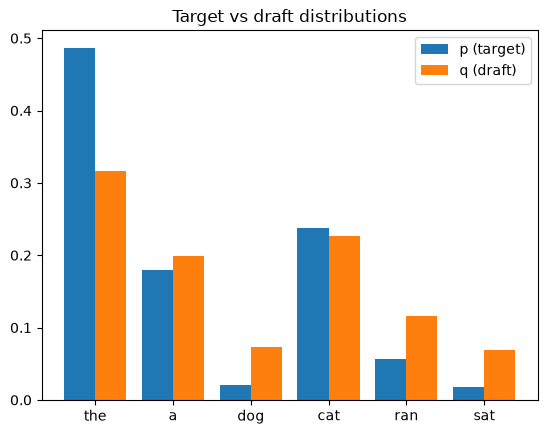

In [ ]:
x = np.arange(len(vocab))
plt.bar(x-0.2, p, 0.4, label='p (target)')
plt.bar(x+0.2, q, 0.4, label='q (draft)')
plt.xticks(x, vocab); plt.legend(); plt.title('Target vs draft distributions');

The paper offers this algorithm for Speculative Sampling.  The rule for each token is:

1. Small/cheap model \(M_q\) proposes a token $i \sim q$
2. Draw $r \sim U(0,1)$
3. **Accept** if $r \le \frac{p_i}{q_i}$ (always accept when $p_i \ge q_i$, since the ratio is $\ge 1$)
4. **Reject** otherwise, and resample from the residual $p' = \text{norm}(\max(0, p - q))$

Tokens that are over-proposed by \(q\) are the ones that will be rejected.  Looking at the distributions, above, we don't have to worry about \(q\) proposing "the" or "cat" too much.  In fact, we can accept "the" and "cat" every time \(q\) proposes them without overshooting the distribution for \(p\).  This is what the step of accepting the token if \(r \le \frac{p_i}{q_i}\) is about.

However, \(q\) proposes some words too often and we could overshoot the distribution of \(p\). We are at risk of ending up with too many occurrences of "a", "dog", "ran", and "sat" if we are using \(q\) to try to achieve the same distribution as \(p\). 
This is why we reject and resample from a different distribution if \(r \gt \frac{p_i}{q_i}\).

Below is what this looks like in code:

In [ ]:
def spec_sample(p, q, rng):
    i = rng.choice(len(q), p=q)        # draft proposes
    r = rng.random()
    if r <= p[i]/q[i]: return i        # accept
    resid = np.maximum(0, p - q)       # residual
    resid = resid/resid.sum()          # normalize
    return rng.choice(len(p), p=resid) # resample

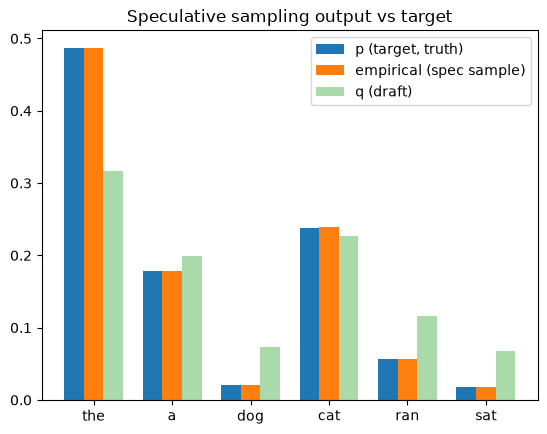

In [ ]:
N = 100_000
samples = np.array([spec_sample(p, q, rng) for _ in range(N)])
emp = np.bincount(samples, minlength=len(p)) / N

x = np.arange(len(vocab))
w = 0.25
plt.bar(x-w, p, w, label='p (target, truth)')
plt.bar(x, emp, w, label='empirical (spec sample)')
plt.bar(x+w, q, w, label='q (draft)', alpha=0.4)
plt.xticks(x, vocab); plt.legend(); plt.title('Speculative sampling output vs target');

### Two ways to break the algorithm

How do we know that our process of resampling from the residual was necessary?  Would we have ended up approximating the distribution of p regardless?  We can "break" the algorithm below, and see that, no, using a different resampling approach gives us the wrong distribution.  This isn't the formal mathematical proof of the paper, but it is a clear visual.

We deliberately break the sampler in two ways and watch the histogram depart from our target distribution p.

- Break A: after rejection, resample from plain p instead of the residual
- Break B: always accept (skip the rejection step entirely)

Let's try resampling just from plain \(p\) instead of from the residual.

In [ ]:
def spec_sample_breakA(p, q, rng):
    i = rng.choice(len(q), p=q)
    r = rng.random()
    if r <= p[i]/q[i]: return i
    return rng.choice(len(p), p=p)  # BUG: resample from p, not residual

Or let's just use q and never reject the tokens it proposes.

In [ ]:
def spec_sample_breakB(p, q, rng):
    i = rng.choice(len(q), p=q)
    return i  # BUG: always keep the draft's proposal

Both of these alternate approaches fail, as you can see in the plot below.  The algorithm proposed (and proven) in the paper is the correct way to go!

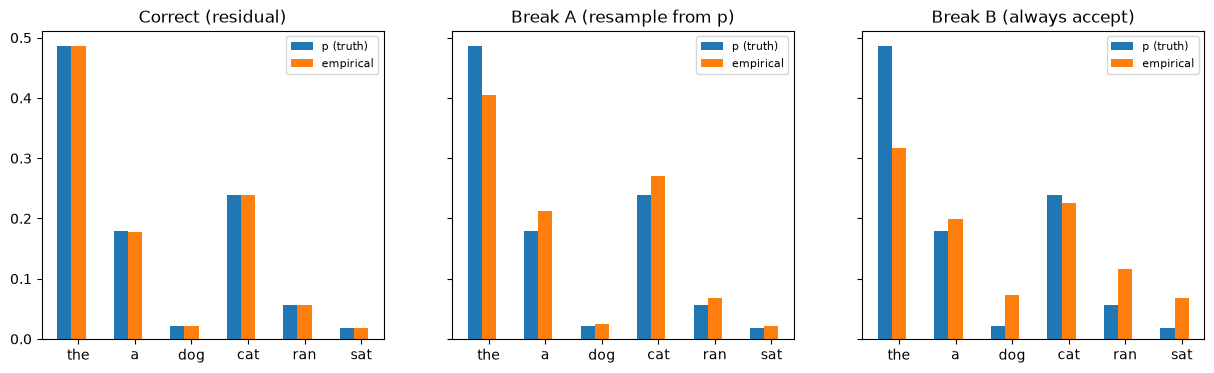

In [ ]:
N = 100_000
samplesA = np.array([spec_sample_breakA(p, q, rng) for _ in range(N)])
samplesB = np.array([spec_sample_breakB(p, q, rng) for _ in range(N)])
empA = np.bincount(samplesA, minlength=len(p)) / N
empB = np.bincount(samplesB, minlength=len(p)) / N

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, emp, title in zip(axes, [emp, empA, empB],
    ['Correct (residual)', 'Break A (resample from p)', 'Break B (always accept)']):
    ax.bar(x-w, p, w, label='p (truth)')
    ax.bar(x, emp, w, label='empirical')
    ax.set_xticks(x); ax.set_xticklabels(vocab)
    ax.set_title(title); ax.legend(fontsize=8)

### The overlap between p and q

The below graphs illustrate the overlap between the 2 distributions, and how setting the residual to \(p - min(p, q)\) gets us to our target distribution \(p\)

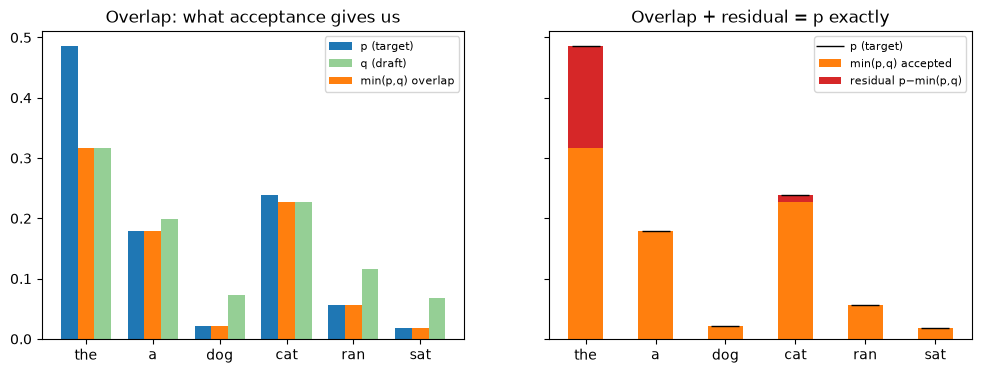

In [ ]:
overlap = np.minimum(p, q)
resid = p - overlap

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].bar(x-w, p, w, label='p (target)')
axes[0].bar(x+w, q, w, label='q (draft)', color='tab:green', alpha=0.5)
axes[0].bar(x, overlap, w, label='min(p,q) overlap', color='tab:orange')
axes[0].set_xticks(x); axes[0].set_xticklabels(vocab)
axes[0].set_title('Overlap: what acceptance gives us'); axes[0].legend(fontsize=8)

axes[1].bar(x, overlap, 0.5, label='min(p,q) accepted', color='tab:orange')
axes[1].bar(x, resid, 0.5, bottom=overlap, label='residual p−min(p,q)', color='tab:red')
axes[1].plot(x, p, 'k_', markersize=20, label='p (target)')
axes[1].set_xticks(x); axes[1].set_xticklabels(vocab)
axes[1].set_title('Overlap + residual = p exactly'); axes[1].legend(fontsize=8)

Acceptance contributes exactly \(\min(p,q)\) for each token: the draft proposes at rate \(q\), and survival at rate \(\min(1, p/q)\) trims that to \(\min(p,q)\). The residual \(p - \min(p,q)\) is nonzero where \(q\) under-proposes. Resampling from the residual supplies the shortfall in order to sum up to \(p\).

The broken variants fail because each mishandles one piece. Break B (always accept) never trims, so over-proposed tokens like "dog" and "sat" stay at \(q\)'s inflated rates. Break A rejects correctly but spreads replacements over all of \(p\), double-counting tokens that were already at full quota.

The total orange area, \(\sum_x \min(p(x), q(x))\), is the overall acceptance rate — the paper calls it \(\alpha\). The more the two distributions overlap, the more guesses survive.  \(\alpha\) is the key to how much of a speedup speculative decoding offers.

## Time Speed Up

What is the best visualization or coding tutorial option to illustrate the time speedup from speculative decoding?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

The speedup story has a special property the correctness story didn't: it rests on formulas with knobs ($\alpha$, $c$, $\gamma$), and the formulas came from a simple probabilistic process you can simulate. That suggests a two-layer approach, and I think one option stands out as best.

**My recommendation: a Monte Carlo "race" simulation.** It mirrors what you did for correctness — verify the formula by experiment — and it produces the most visceral picture:

1. Simulate Algorithm 1's accept/reject process directly: each step, flip coins with acceptance probability $\alpha$; count how many of the $\gamma$ guesses survive (capped geometric). That's ~5 lines of numpy.
2. Track cumulative time for both methods on the same token budget: standard decoding pays $1$ per token; speculative pays $\gamma c + 1$ per *step* but emits a variable number of tokens.
3. Plot **tokens generated vs. time elapsed** as two racing lines. Standard decoding is a straight line; speculative is a steeper line with slightly lumpy progress. The gap between them *is* the walltime improvement.
4. Then the payoff: overlay the empirical speedup on the theoretical curve $\frac{1-\alpha^{\gamma+1}}{(1-\alpha)(\gamma c+1)}$ swept over $\gamma$, and watch the dots land on the line — Theorem 3.8 verified by simulation, just like your histogram verified Appendix A.1.

Why this beats the alternatives:

- It reuses the pedagogical pattern your tutorial has already established (simulate, then check against theory), so it feels coherent rather than bolted on.
- The capped-geometric structure (Equation 1) falls out *visibly*: students see runs of accepts ending in a reject, and the per-step token counts histogram into the geometric shape.
- It naturally demonstrates the paper's most counterintuitive experimental finding: plug in T5-large's numbers ($\alpha=0.82, c=0.11$) vs T5-small's ($\alpha=0.75, c=0.02$) from Table 4 and watch the *worse* guesser win the race. That single comparison teaches the whole $\alpha$-vs-$c$ tradeoff.

**Second choice: an interactive $\gamma$-chooser dashboard** (sliders for $\alpha$ and $c$, live plot of speedup vs $\gamma$, marker on the optimum). It reproduces Figures 2–4 interactively and is great for building intuition about *why* the optimal $\gamma$ is finite — pushing $\gamma$ higher keeps helping until the drafter's cost $\gamma c$ and the likelihood of wasted guesses catch up. But it's a formula-explorer: it shows the theory's *shape* without demonstrating the theory is *true*. It would make a fine FastHTML follow-up to the race, reusing the JupyUvi setup from your first visualization.

The weakest option here would be a static reproduction of the paper's figures — it adds nothing over the paper itself.

One honest caveat to state in the tutorial: the simulation takes the walltime model as given (a step costs $\gamma c + 1$, parallel verification is free). It verifies the *math on top of that model*, not the hardware claim itself — that's what the paper's Table 4 (theory vs. measured runtimes) is for, and it's worth pointing students there to close the loop.

Want to start with step 1, the capped-geometric step simulator?

I would like to go with the interactive gamma-chooser dashboard, built in FastHTML.  Can you hlep me with this?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Happy to! Let's build it in small steps, reusing the JupyUvi pattern from your first viz. Here's the shape I have in mind — tell me if it matches what you pictured:

**The dashboard:** two sliders ($\alpha$ from ~0.05 to 0.95, $c$ from 0 to ~0.2), and on any change, HTMX fetches a re-rendered plot of speedup vs $\gamma$ (Theorem 3.8: $\frac{1-\alpha^{\gamma+1}}{(1-\alpha)(\gamma c + 1)}$) with a marker on the optimal integer $\gamma$. Optionally a second panel showing expected tokens per step (Equation 1) so students can see *why* the speedup saturates.

**Build order:**
1. The pure math: a function computing speedup for a range of $\gamma$ values, and the optimum — testable in the notebook with values from the paper's Table 4 before any web code
2. A function rendering that as a matplotlib figure → SVG/PNG string
3. The FastHTML app: sliders + an HTMX-swapped image, served via JupyUvi like before

Step 1 is the foundation, and it's a nice self-check: with T5-small EnDe numbers ($\alpha=0.75$, $c=0.02$) the paper says the expected improvement is ~3.2X at $\gamma=7$, so you can verify your function against Table 4 immediately.

Have a go at the speedup function — it just needs to take `alpha`, `c`, and an array of `gamma` values, and return the speedup for each. The formula is:

$$\text{speedup}(\gamma) = \frac{1-\alpha^{\gamma+1}}{(1-\alpha)(\gamma c + 1)}$$

With numpy, `gammas = np.arange(1, 21)` vectorizes the whole thing in one line. Then try `alpha=0.75, c=0.02` and check the value at $\gamma=7$ lands near 3.2, and `np.argmax` finds the optimum.

Give it a shot and share what you get — then we'll wrap it in a plot function.

Okay, let's get started on the Monte carlo race simulation

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Let's build it in small pieces, starting with the heart of it: simulating **one step** of Algorithm 1.

Recall the process: the drafter proposes $\gamma$ tokens; each is accepted independently with probability $\alpha$ (that's the i.i.d. simplifying assumption from Section 3.1); the step ends at the first rejection. If $n$ guesses survive, the step emits $n + 1$ tokens — the accepted guesses plus the big model's correction (or bonus token if all $\gamma$ survived).

So the quantity to simulate is: *how many tokens does one step emit?* It's a sequence of coin flips stopping at the first failure, capped at $\gamma$ successes.

A nice trick for this in numpy without a loop: draw all $\gamma$ uniforms at once, compare to $\alpha$, and find the index of the first `False`. Something like `np.argmax(flips == False)` gives you that index — with one subtlety you'll need to handle: what does `argmax` return when *all* the flips are `True`?

Try writing a function `step_tokens(alpha, gamma, rng)` that returns the number of tokens (between $1$ and $\gamma+1$) from one simulated step. Then a quick sanity check: run it 100k times with $\alpha=0.8, \gamma=5$ and compare the mean against Equation 1, $\frac{1-\alpha^{\gamma+1}}{1-\alpha} \approx 3.69$ (the paper's Table 1 row).

If you'd rather I sketch the function, say the word — but I suspect you'll enjoy the `argmax` subtlety.

In [49]:
import numpy as np

rng = np.random.default_rng()

def step_tokens(alpha, gamma, rng):
    # Generate an array of individual flips
    flips = rng.random(gamma) < alpha
    ans = np.argmax(~flips)
    # if all are true, argmax returns 0
    if ans == 0 and flips[0]:
        ans = len(flips)
    return ans + 1


In [46]:
N = 100_000
test = np.array([step_tokens(0.8, 5, rng) for _ in range(N)])
test.mean()

np.float64(3.6831)

Ok, what next?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Your `step_tokens` is correct, and the sanity check nails it: 3.6831 vs the theoretical $\frac{1-0.8^6}{0.2} \approx 3.687$. The `argmax` handling is right — one tiny style note: `np.argmax(~flips)` is the idiomatic spelling of `flips == False`.

Now for the **race** itself. The idea: both methods generate the same total number of tokens (say `T = 200`), and we track *cumulative time* as each token arrives.

- **Standard decoding**: token $k$ arrives at time $k$ (one big-model run each, using $M_p$'s runtime as our time unit). Trivial — that's just `np.arange(1, T+1)`.
- **Speculative**: each step costs $\gamma c + 1$ time units and emits `step_tokens(...)` tokens. So you loop: simulate a step, advance the clock by $\gamma c + 1$, and record the arrival time for each token that step emitted (they all arrive when the step *finishes*, so a step emitting 4 tokens produces 4 points at the same time — that's what makes the line "lumpy").

Try writing `race(alpha, c, gamma, T, rng)` that returns an array of arrival times for the speculative side — the time at which each of the first `T` tokens is done. (Simplest structure: keep stepping until you've accumulated ≥ `T` tokens, collecting `[t_now] * n_tokens` as you go, then trim to `T`.)

Then plot both: `plt.plot(times, np.arange(1, T+1))` for each method — time on x, tokens on y. Use $\alpha=0.75, c=0.02, \gamma=7$ (T5-small's numbers from Table 4) and see if the gap looks like the ~3.2X the paper predicts.

Two things to watch:
- The last step may overshoot `T` — trimming the list is fine.
- Keep `rng` as a parameter like you did before, so the race is reproducible when you seed it.